## Environment Configuration and verification

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Data Loading

df = pd.read_csv("india_multi_agency_edd_dataset_v2.csv")
print(df.shape)

(210850, 21)


In [3]:
# Data Diagnostics

df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 210850 entries, 0 to 210849
Data columns (total 21 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Order_ID                210850 non-null  str    
 1   Delivery_Partner        210850 non-null  str    
 2   Origin_City             210850 non-null  str    
 3   Origin_Pincode          210850 non-null  int64  
 4   Destination_City        210850 non-null  str    
 5   Destination_Pincode     210850 non-null  int64  
 6   Logistics_Zone          210850 non-null  str    
 7   Distance_km             210850 non-null  float64
 8   Shipment_Mode           210850 non-null  str    
 9   Weight_kg               210850 non-null  float64
 10  Warehouse_Handling_Fee  210850 non-null  float64
 11  Fuel_Surcharge          210850 non-null  float64
 12  Freight_Cost            210850 non-null  float64
 13  Insurance_Fee           210850 non-null  float64
 14  Total_Shipping_Cost     210850 

,Origin_Pincode,Destination_Pincode,Distance_km,Weight_kg,Warehouse_Handling_Fee,Fuel_Surcharge,Freight_Cost,Insurance_Fee,Total_Shipping_Cost,Transit_Time_Hours,Actual_Delivery_Days,Is_Delayed_SLA,Rating_Stars
count,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,210850.000000,204505.000000
mean,454308.667128,455369.765658,1253.209784,12.538129,29.931570,125.302815,2069.283178,103.464242,2172.747420,58.040700,2.418364,0.034892,4.635505
std,199117.776816,199251.554299,719.316951,7.194550,11.544629,82.982259,1372.291824,68.614599,1440.906423,32.378141,1.349085,0.183507,0.752739
min,110004.000000,110001.000000,5.010000,0.100000,10.000000,0.510000,24.070000,1.200000,25.270000,0.370000,0.020000,0.000000,1.000000
25%,282518.000000,283025.000000,629.720000,6.310000,19.900000,57.380000,1025.215000,51.262500,1076.477500,31.730000,1.320000,0.000000,4.000000
50%,453157.000000,455467.000000,1254.110000,12.530000,29.930000,114.170000,1882.005000,94.100000,1976.105000,55.420000,2.310000,0.000000,5.000000
75%,626719.000000,628408.250000,1876.160000,18.760000,39.900000,180.700000,2745.552500,137.280000,2882.832500,81.000000,3.380000,0.000000,5.000000
max,799990.000000,799998.000000,2499.990000,25.000000,50.000000,374.390000,6603.010000,330.150000,6933.160000,211.280000,8.800000,1.000000,5.000000


##  Data Cleaning and statistical core maps

In [4]:
# Null Analysis

df.isnull().sum()

Order_ID                       0
Delivery_Partner               0
Origin_City                    0
Origin_Pincode                 0
Destination_City               0
Destination_Pincode            0
Logistics_Zone                 0
Distance_km                    0
Shipment_Mode                  0
Weight_kg                      0
Warehouse_Handling_Fee         0
Fuel_Surcharge                 0
Freight_Cost                   0
Insurance_Fee                  0
Total_Shipping_Cost            0
Festival_Peak             147569
Transit_Time_Hours             0
Actual_Delivery_Days           0
Is_Delayed_SLA                 0
Rating_Stars                6345
Review_Text                10417
dtype: int64

In [5]:
# filling Nulls

df["Festival_Peak"] = df["Festival_Peak"].fillna("Normal_Period")

# for Rating_stars

grouped_logistics = df.groupby(["Delivery_Partner", "Is_Delayed_SLA"])
ratings_column_grouped = grouped_logistics["Rating_Stars"]

conditional_medians = ratings_column_grouped.transform("median")

df["Rating_Stars"] = df["Rating_Stars"].fillna(conditional_medians)

# checking

df["Rating_Stars"].isnull().sum()
df.isnull().sum()

Order_ID                      0
Delivery_Partner              0
Origin_City                   0
Origin_Pincode                0
Destination_City              0
Destination_Pincode           0
Logistics_Zone                0
Distance_km                   0
Shipment_Mode                 0
Weight_kg                     0
Warehouse_Handling_Fee        0
Fuel_Surcharge                0
Freight_Cost                  0
Insurance_Fee                 0
Total_Shipping_Cost           0
Festival_Peak                 0
Transit_Time_Hours            0
Actual_Delivery_Days          0
Is_Delayed_SLA                0
Rating_Stars                  0
Review_Text               10417
dtype: int64

#### Computing and Plotting the Correlation Matrix

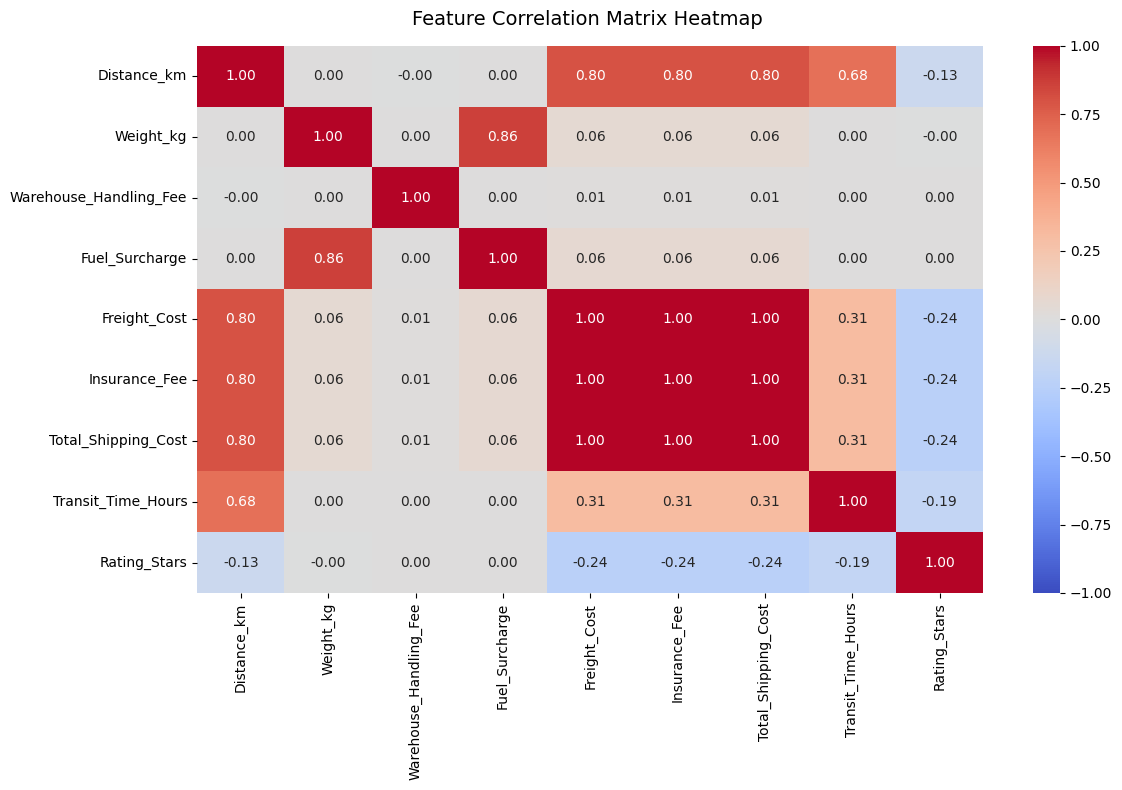

In [6]:
# Isolating numerical feature columns

numerical_features = df[
    [
        "Distance_km",
        "Weight_kg",
        "Warehouse_Handling_Fee",
        "Fuel_Surcharge",
        "Freight_Cost",
        "Insurance_Fee",
        "Total_Shipping_Cost",
        "Transit_Time_Hours",
        "Rating_Stars",
    ]
]

# Computing The linear correlation cefficients matrix
correlation_matrix = numerical_features.corr()

# ploting
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)


plt.title("Feature Correlation Matrix Heatmap ", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## One Hot Encoding


In [7]:
# Dummy Encoding

categorical_columns = [
    "Delivery_Partner",
    "Shipment_Mode",
    "Festival_Peak",
    "Origin_City",
    "Destination_City",
    "Logistics_Zone",
]
df_encoded = pd.get_dummies(
    df, columns=categorical_columns, drop_first=True, dtype=float
)

# print("Categorical variables expanded successfully.")
print(f"Original dataframe dimensions :{df.shape}")
print(f"Encoded dataframe dimensions :{df_encoded.shape}")

Original dataframe dimensions :(210850, 21)
Encoded dataframe dimensions :(210850, 49)


In [8]:
# Scaling 
continuous_features = [
    "Distance_km",
    "Weight_kg",
    "Warehouse_Handling_Fee",
    "Fuel_Surcharge",
    "Freight_Cost",
    "Insurance_Fee",
]

index_range = int(0.80 * len(df_encoded))

for column in continuous_features:
    mean_val = df_encoded[column].iloc[:index_range].mean()
    std_val = df_encoded[column].iloc[:index_range].std()
    df_encoded[column] = (df_encoded[column] - mean_val) / std_val

print(df_encoded[continuous_features].iloc[:index_range].agg(["mean", "std"]).round(2))


      Distance_km  Weight_kg  Warehouse_Handling_Fee  Fuel_Surcharge  \
mean         -0.0       -0.0                    -0.0             0.0   
std           1.0        1.0                     1.0             1.0   

      Freight_Cost  Insurance_Fee  
mean          -0.0           -0.0  
std            1.0            1.0  


In [9]:
# Train, Test Separation
columns_to_drop = [
    "Order_ID",
    "Review_Text",
    "Transit_Time_Hours",
    "Actual_Delivery_Days",
    "Is_Delayed_SLA",
    "Rating_Stars",
    "Origin_Pincode",
    "Destination_Pincode",
    "Total_Shipping_Cost",  
]

X = df_encoded.drop(columns=columns_to_drop)
y = df_encoded["Transit_Time_Hours"]

X_train = np.array(X.iloc[:index_range], dtype=np.float64)
X_test = np.array(X.iloc[index_range:], dtype=np.float64)

y_train = np.array(y.iloc[:index_range], dtype=np.float64)
y_test = np.array(y.iloc[index_range:], dtype=np.float64)

print(f"X_train array dimension : {X_train.shape} and y_train size: {y_train.shape}")
print(f"X_test array dimension :   {X_test.shape}  and y_test size:   {y_test.shape}")


X_train array dimension : (168680, 40) and y_train size: (168680,)
X_test array dimension :   (42170, 40)  and y_test size:   (42170,)


##  Regression - Linear Model from Scratch

In [10]:
# Weight vector and bias initialization

features_number = X_train.shape[1]

w = np.zeros(features_number)
b = 0

print(f"Weight vector (w) dimension : {w.shape} ")
print(f"Bias coefficient (b) : {b} (Scalar origin point)")

Weight vector (w) dimension : (40,) 
Bias coefficient (b) : 0 (Scalar origin point)


### Defining Important Functions

In [11]:
### Defining y Prediction Function


def y_predict(X, w, b):

    y_pred = np.dot(X, w) + b

    return y_pred


### Mean Squared Error


def mse_loss(y_true, y_pred):

    m = len(y_true)
    errors = y_pred - y_true
    loss = (1 / (m)) * np.sum(errors**2)

    return loss


### Gradient of Loss With Respect to Weights


def dLdw(X, y_true, y_pred):

    m = len(y_true)
    errors = y_pred - y_true
    dldw = (2 / m) * np.dot(X.T, errors)

    return dldw


### Gradient of Loss With Respect to Bias


def dLdb(y_true, y_pred):

    m = len(y_true)
    errors = y_pred - y_true
    dldb = (2 / m) * np.sum(errors)

    return dldb

### Implementing Gradient Descent 

In [12]:
# Defining Gradient Descent Function


def gradient_descent(X_tr, y_tr, X_te, y_te, learning_rt=0.01, epochs=500):

    # Weight vector and bias initialization

    w = np.zeros(X_tr.shape[1])
    b = 0.0
    # Tracking Arrays

    train_loss_history = []
    test_loss_history = []

    # Updating Parameters

    for epoch in range(epochs):

        y_pred_train = y_predict(X_tr, w, b)
        y_pred_test = y_predict(X_te, w, b)

        loss_train = mse_loss(y_tr, y_pred_train)
        loss_test = mse_loss(y_te, y_pred_test)

        train_loss_history.append(loss_train)
        test_loss_history.append(loss_test)

        gradient_w = dLdw(X_tr, y_tr, y_pred_train)
        gradient_b = dLdb(y_tr, y_pred_train)

        
        # Back Tracking
        learning_rate=learning_rt

        beta=0.5  
        c=0.005
        while True:
            if mse_loss(y_tr, y_predict(X_tr, w - (learning_rate * gradient_w), b - (learning_rate * gradient_b))) <= loss_train - (c * learning_rate * (np.sum(gradient_w ** 2) + (gradient_b ** 2))):
                break
            learning_rate *= beta
            if learning_rate < 1e-7:
                break
        
        w = w - (learning_rate * gradient_w)
        b = b - (learning_rate * gradient_b)

    return w, b, train_loss_history, test_loss_history

In [13]:
# Execution
weight_gd, bias_gd, train_losses, test_losses = gradient_descent(
    X_train, y_train, X_test, y_test, learning_rt=0.1, epochs=3500
)

print(f"Optimized Bias Intercept (b): {bias_gd:.4f}")
print(f"First 5 Feature Weights (w):  {weight_gd[:5].round(4)}")
print(f"Final Iteration Train RMSE:   {np.sqrt(train_losses[-1]):.4f}")
print(f"Final Iteration Test RMSE:    {np.sqrt(test_losses[-1]):.4f}")


Optimized Bias Intercept (b): 85.5373
First 5 Feature Weights (w):  [ 3.92843e+01  3.46000e-02  1.63000e-01  1.28190e+00 -1.07628e+01]
Final Iteration Train RMSE:   8.6867
Final Iteration Test RMSE:    8.7013


## Lasso (L1-Regularized) Linear Regression Using Proximal Gradient Descent

In [14]:
# Defining Lasso Gradient Descent Function


def lasso_gradient_descent(X_tr, y_tr, X_te, y_te, learning_rt=0.1, epochs=1000, l1_penalty=0.1):

    #Initialize local parameters
    num_features = X_tr.shape[1]
    w = np.zeros(num_features)
    b = 0.0

    #Tracking Arrays

    train_loss_history = []
    test_loss_history = []

    # Updating Parameters

    for epoch in range(epochs):

        # Compute forward pass matrix predictions across both partitions
        y_pred_train = y_predict(X_tr, w, b)
        y_pred_test = y_predict(X_te, w, b)

        # Calculate standard Mean Squared Error
        loss_train = mse_loss(y_tr, y_pred_train)
        loss_test = mse_loss(y_te, y_pred_test)

        train_loss_history.append(loss_train)
        test_loss_history.append(loss_test)

        # Gradients (MSE derivatives)
        gradient_w = dLdw(X_tr, y_tr, y_pred_train)
        gradient_b = dLdb(y_tr, y_pred_train)

        # Back Tracking
        learning_rate = learning_rt

        beta = 0.5
        while True:
            w_step = w - (learning_rate * gradient_w)
            shrink = np.abs(w_step) - (learning_rate * l1_penalty)
            w_new = np.sign(w_step) * shrink * (shrink > 0)
            b_new = b - (learning_rate * gradient_b)

            dw = w_new - w
            db = b_new - b

            if mse_loss(y_tr, y_predict(X_tr, w_new, b_new)) <= loss_train + np.dot(gradient_w, dw) + (gradient_b * db) + ((np.sum(dw ** 2) + (db ** 2)) / (2 * learning_rate)):
                break
            learning_rate *= beta
            if learning_rate < 1e-7:
                break

        w = w_new
        b = b_new

    return w, b, train_loss_history, test_loss_history

In [15]:
# Execution And RMSE vs Alpha Ploting

val_index = int(0.80 * len(X_train))

X_train_in = X_train[:val_index]
X_val = X_train[val_index:]

y_train_in = y_train[:val_index]
y_val = y_train[val_index:]

alphas = np.logspace(-5, 1, 13)

train_rmse_history = []
val_rmse_history = []

for alpha in alphas:

    weight_lasso, bias_lasso, train_loss, val_loss = lasso_gradient_descent(
        X_train_in, y_train_in, X_val, y_val, learning_rt=0.1, epochs=1500, l1_penalty=alpha
    )

    train_rmse_history.append(np.sqrt(train_loss[-1]))
    val_rmse_history.append(np.sqrt(val_loss[-1]))
    zero_weights_count = np.sum(np.abs(weight_lasso) < 1e-4)
    print(f"Alpha: {alpha:<6} -> Final Train RMSE: {np.sqrt(train_loss[-1]):.4f} | Final Validation RMSE: {np.sqrt(val_loss[-1]):.4f} | Features Pruned to Zero: {zero_weights_count}/{len(weight_lasso)}")

best_alpha = alphas[np.argmin(val_rmse_history)]
print(f"Best Alpha (Lowest Validation RMSE): {best_alpha}")

Alpha: 1e-05  -> Final Train RMSE: 8.6837 | Final Validation RMSE: 8.7604 | Features Pruned to Zero: 0/40
Alpha: 3.1622776601683795e-05 -> Final Train RMSE: 8.6837 | Final Validation RMSE: 8.7604 | Features Pruned to Zero: 0/40
Alpha: 0.0001 -> Final Train RMSE: 8.6836 | Final Validation RMSE: 8.7603 | Features Pruned to Zero: 0/40
Alpha: 0.00031622776601683794 -> Final Train RMSE: 8.6834 | Final Validation RMSE: 8.7600 | Features Pruned to Zero: 0/40
Alpha: 0.001  -> Final Train RMSE: 8.6826 | Final Validation RMSE: 8.7593 | Features Pruned to Zero: 0/40
Alpha: 0.0031622776601683794 -> Final Train RMSE: 8.6805 | Final Validation RMSE: 8.7571 | Features Pruned to Zero: 0/40
Alpha: 0.01   -> Final Train RMSE: 8.6756 | Final Validation RMSE: 8.7521 | Features Pruned to Zero: 0/40
Alpha: 0.03162277660168379 -> Final Train RMSE: 8.6729 | Final Validation RMSE: 8.7486 | Features Pruned to Zero: 28/40
Alpha: 0.1    -> Final Train RMSE: 8.6756 | Final Validation RMSE: 8.7497 | Features Pruned

In [16]:
weight_lasso, bias_lasso, train_loss, test_loss = lasso_gradient_descent(
    X_train, y_train, X_test, y_test, learning_rt=0.1, epochs=1500, l1_penalty=best_alpha
)

zero_weights_count = np.sum(np.abs(weight_lasso) < 1e-4)

print(f"Final Train RMSE: {np.sqrt(train_loss[-1]):.4f}")
print(f"Final Test RMSE:  {np.sqrt(test_loss[-1]):.4f}")
print(f"Features Pruned to Zero: {zero_weights_count}/{len(weight_lasso)}")

Final Train RMSE: 8.6885
Final Test RMSE:  8.7004
Features Pruned to Zero: 30/40


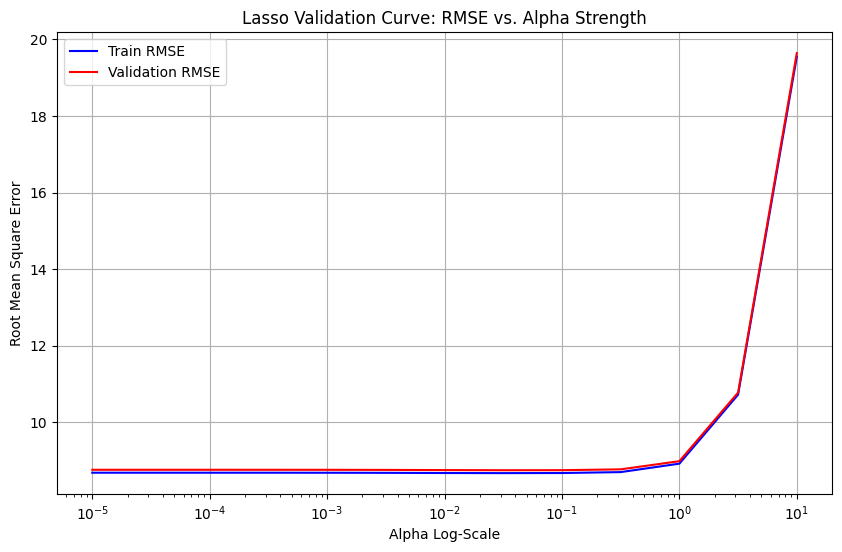

In [17]:
# RMSE vs Alpha Plot

plt.figure(figsize=(10,6))
plt.plot(alphas,train_rmse_history,color="b",label='Train RMSE')
plt.plot(alphas,val_rmse_history,color="r",label='Validation RMSE')
plt.xscale('log')
plt.xlabel('Alpha Log-Scale')
plt.ylabel('Root Mean Square Error')
plt.title('Lasso Validation Curve: RMSE vs. Alpha Strength')
plt.grid()
plt.legend()
plt.show()

### Comparison With Other Models

In [18]:

from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet, Lasso
from sklearn.metrics import mean_squared_error, r2_score



# Instantiate baseline architectures
bagging_model = BaggingRegressor(estimator=LinearRegression(), n_estimators=50, random_state=42, n_jobs=-1)
rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
ridge_model = Ridge(alpha=0.01)
elastic_model = ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=42)
sk_lasso = Lasso(alpha=0.001, max_iter=1000, random_state=42)

# Parallel training passes
bagging_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)
elastic_model.fit(X_train, y_train)
sk_lasso.fit(X_train, y_train)

# Collect predictions
bagging_preds = bagging_model.predict(X_test)
rf_preds = rf_model.predict(X_test)
ridge_preds = ridge_model.predict(X_test)
elastic_preds = elastic_model.predict(X_test)
sk_lasso_preds = sk_lasso.predict(X_test)

# Map performance metrics
models_metrics = {
    "Bagging Regressor (Linear)": (np.sqrt(mean_squared_error(y_test, bagging_preds)), r2_score(y_test, bagging_preds)),
    "Random Forest Regressor": (np.sqrt(mean_squared_error(y_test, rf_preds)), r2_score(y_test, rf_preds)),
    "Ridge Regression (L2)": (np.sqrt(mean_squared_error(y_test, ridge_preds)), r2_score(y_test, ridge_preds)),
    "ElasticNet (L1 + L2)": (np.sqrt(mean_squared_error(y_test, elastic_preds)), r2_score(y_test, elastic_preds)),
    "Scikit-Learn Lasso (L1)": (np.sqrt(mean_squared_error(y_test, sk_lasso_preds)), r2_score(y_test, sk_lasso_preds))
}

# ----------------------------------------------------------------------
# TRAILING EVALUATION PROFILE FOR FROM-SCRATCH MODELS
# ----------------------------------------------------------------------
# Custom Baseline Gradient Descent from Scratch 
y_pred_scratch_gd = y_predict(X_test, weight_gd, bias_gd)
scratch_gd_rmse = np.sqrt(mean_squared_error(y_test, y_pred_scratch_gd))
scratch_gd_r2 = r2_score(y_test, y_pred_scratch_gd)
models_metrics["Custom GD from Scratch"] = (scratch_gd_rmse, scratch_gd_r2)

# Custom Lasso from Scratch
y_pred_scratch_lasso = y_predict(X_test, weight_lasso, bias_lasso)
scratch_lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_scratch_lasso))
scratch_lasso_r2 = r2_score(y_test, y_pred_scratch_lasso)
models_metrics["Custom Lasso from Scratch"] = (scratch_lasso_rmse, scratch_lasso_r2)

# Final summary table layout
comparison_df = pd.DataFrame.from_dict(
    models_metrics, orient='index', columns=['Test RMSE (Hours)', 'Test R² Score']
)

print("\n======================= MASTER PERFORMANCE EVALUATION MATRIX =======================")
print(comparison_df.round(4))
print("====================================================================================")



======================= MASTER PERFORMANCE EVALUATION MATRIX =======================
                            Test RMSE (Hours)  Test R² Score
Bagging Regressor (Linear)             8.7013         0.9280
Random Forest Regressor                8.7625         0.9270
Ridge Regression (L2)                  8.7014         0.9280
ElasticNet (L1 + L2)                   8.7378         0.9274
Scikit-Learn Lasso (L1)                8.7012         0.9280
Custom GD from Scratch                 8.7013         0.9280
Custom Lasso from Scratch              8.7004         0.9280


## Binary Classification from Scratch

In [19]:
# Isolate your classification target arrays from your encoded dataframe

y_train_clf = df_encoded['Is_Delayed_SLA'].iloc[:index_range].to_numpy(dtype=np.float64)
y_test_clf = df_encoded['Is_Delayed_SLA'].iloc[index_range:].to_numpy(dtype=np.float64)

In [20]:
#Sigmoid Activation and Binary Cross-Entropy Loss Functions from Scratch

def sigmoid(z):
    """Maps any continuous matrix value to strict probability boundaries between 0.0 and 1.0."""
    # np.clip prevents exponential floating-point explosion (overflow errors) in memory
    z_clipped = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z_clipped))


def binary_cross_entropy(y_true, y_pred):
    """Computes the logarithmic penalty distance between two binary distributions."""
    m = len(y_true)
    
    
    y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
    
    # Explicit implementation of the vectorised log-loss formula
    loss = - (1 / m) * np.sum(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))
    return loss




In [21]:
# Partial Derivative Solvers for Binary Cross-Entropy Loss Space

def dLdw_clf(X, y_true, y_pred):
    """Computes gradient of log-loss with respect to weights: dLdw = (1 / m) * X.T . (y_pred - y_true)"""
    m = len(y_true)
    errors = y_pred - y_true
    dldw = (1 / m) * np.dot(X.T, errors)
    return dldw


def dLdb_clf(y_true, y_pred):
    """Computes gradient of log-loss with respect to intercept bias: dLdb = (1 / m) * sum(y_pred - y_true)"""
    m = len(y_true)
    errors = y_pred - y_true
    dldb = (1 / m) * np.sum(errors)
    return dldb

print("Classification gradient functions successfully compiled.")


Classification gradient functions successfully compiled.


In [22]:
#Custom Logistic Regression Engine from Scratch via Batch Gradient Descent

def logistic_regression(X_tr, y_tr, X_te, y_te, learning_rate=0.05, epochs=1500):
   
    num_features = X_tr.shape[1]
    w = np.zeros(num_features)
    b = 0.0
    
    # Setup tracking history profiles for Log-Loss diagnostics
    train_loss_history = []
    test_loss_history = []
    
    print(f"Initializing Logistic Regression model pipeline... Features: {num_features}")
    print(f"Hyperparameters: Learning Rate = {learning_rate} | Total Epochs = {epochs}\n")
    
    # Initiate parameter optimization loop
    for epoch in range(epochs):
  
        z_train = np.dot(X_tr, w) + b
        z_test = np.dot(X_te, w) + b
        
        y_pred_train = sigmoid(z_train)
        y_pred_test = sigmoid(z_test)
        
        loss_train = binary_cross_entropy(y_tr, y_pred_train)
        loss_test = binary_cross_entropy(y_te, y_pred_test)
        
        train_loss_history.append(loss_train)
        test_loss_history.append(loss_test)
        
        gradient_w = dLdw_clf(X_tr, y_tr, y_pred_train)
        gradient_b = dLdb_clf(y_tr, y_pred_train)
        
        w = w - (learning_rate * gradient_w)
        b = b - (learning_rate * gradient_b)
        
        if epoch % 200 == 0:
            print(f"Epoch {epoch:04d}/{epochs} -> Train Log-Loss: {loss_train:.5f} | Test Log-Loss: {loss_test:.5f}")
            
    return w, b, train_loss_history, test_loss_history



In [23]:
# Executing your custom classification optimization loop
w_clf, b_clf, train_losses_clf, test_losses_clf = logistic_regression(
    X_train, y_train_clf, X_test, y_test_clf, learning_rate=0.1, epochs=1000
)

Initializing Logistic Regression model pipeline... Features: 40
Hyperparameters: Learning Rate = 0.1 | Total Epochs = 1000



Epoch 0000/1000 -> Train Log-Loss: 0.69315 | Test Log-Loss: 0.69315
Epoch 0200/1000 -> Train Log-Loss: 0.09810 | Test Log-Loss: 0.09654
Epoch 0400/1000 -> Train Log-Loss: 0.08752 | Test Log-Loss: 0.08584
Epoch 0600/1000 -> Train Log-Loss: 0.08279 | Test Log-Loss: 0.08110
Epoch 0800/1000 -> Train Log-Loss: 0.07972 | Test Log-Loss: 0.07806


In [24]:
#  Confusion Matrix Extraction from Scratch

# Compute continuous probability vectors across the testing data slice
# Using the optimized classification parameters (w_clf, b_clf)

z_test_clf = np.dot(X_test, w_clf) + b_clf
y_prob_test = sigmoid(z_test_clf)

y_pred_clf = (y_prob_test >= 0.3).astype(np.float64) # Threshold 0.3

# Initialize the four primary spatial matrix accumulators
TP = 0.0
FP = 0.0
TN = 0.0
FN = 0.0

#  Iteratively compare predicted classes against true class targets
for i in range(len(y_test_clf)):
    true_label = y_test_clf[i]
    pred_label = y_pred_clf[i]
    
    if true_label == 1.0 and pred_label == 1.0:
        TP += 1.0
    elif true_label == 0.0 and pred_label == 1.0:
        FP += 1.0
    elif true_label == 0.0 and pred_label == 0.0:
        TN += 1.0
    elif true_label == 1.0 and pred_label == 0.0:
        FN += 1.0

# Format and render the final contingency grid
print("================ CONFUSION MATRIX PROFILE ================")
print(f"True Negatives (TN)  : {int(TN):<8} | False Positives (FP) : {int(FP)}")
print(f"False Negatives (FN) : {int(FN):<8} | True Positives (TP)  : {int(TP)}")
print("==========================================================")
print(f"Total Evaluated Test Rows: {int(TN + FP + FN + TP)}")



================ CONFUSION MATRIX PROFILE ================
True Negatives (TN)  : 40323    | False Positives (FP) : 396
False Negatives (FN) : 710      | True Positives (TP)  : 741
Total Evaluated Test Rows: 42170


In [25]:

# Classification Metric 

# Compute foundational statistical ratios 
accuracy = (TP + TN) / (TP + TN + FP + FN)

# Prevent division-by-zero errors in case an accumulator tier is empty
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

# Final analytical summary grid
print("============== FINAL CLASSIFICATION REPORT ==============")
print(f"Overall Model Accuracy : {accuracy * 100:.2f}%")
print(f"Precision (Class 1)    : {precision:.4f}")
print(f"Recall (Sensitivity)   : {recall:.4f}")
print(f"F1-Score (Harmonic Mean): {f1_score:.4f}")
print("=========================================================")


============== FINAL CLASSIFICATION REPORT ==============
Overall Model Accuracy : 97.38%
Precision (Class 1)    : 0.6517
Recall (Sensitivity)   : 0.5107
F1-Score (Harmonic Mean): 0.5726


## Comparison Of Models

In [26]:
# Comparative Classification Benchmark Study using Scikit-Learn
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Instantiate unweighted benchmark algorithms
bagging_clf = BaggingClassifier(estimator=LogisticRegression(max_iter=1000), n_estimators=50, random_state=42, n_jobs=-1)
rf_clf = RandomForestClassifier(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)

# Execute parallel training operations
bagging_clf.fit(X_train, y_train_clf)
rf_clf.fit(X_train, y_train_clf)

# Extract continuous probabilities for fair threshold comparison
bagging_probs = bagging_clf.predict_proba(X_test)[:, 1]
rf_probs = rf_clf.predict_proba(X_test)[:, 1]
custom_probs = y_prob_test  # From Cell 24

def get_metrics_at_tau(y_true, probs, tau):
    preds = (probs >= tau).astype(np.float64)
    return (
        accuracy_score(y_true, preds),
        precision_score(y_true, preds, zero_division=0),
        recall_score(y_true, preds, zero_division=0),
        f1_score(y_true, preds, zero_division=0)
    )

# Fair comparison at matched threshold tau = 0.30 (and baseline tau = 0.50)
clf_metrics = {
    "Bagging Classifier (Logistic, tau=0.3)": get_metrics_at_tau(y_test_clf, bagging_probs, 0.3),
    "Random Forest Classifier (tau=0.3)": get_metrics_at_tau(y_test_clf, rf_probs, 0.3),
    "Custom Logistic from Scratch (tau=0.3)": get_metrics_at_tau(y_test_clf, custom_probs, 0.3),
    "Bagging Classifier (Logistic, tau=0.5)": get_metrics_at_tau(y_test_clf, bagging_probs, 0.5),
    "Random Forest Classifier (tau=0.5)": get_metrics_at_tau(y_test_clf, rf_probs, 0.5),
    "Custom Logistic from Scratch (tau=0.5)": get_metrics_at_tau(y_test_clf, custom_probs, 0.5),
}

comparison_clf_df = pd.DataFrame.from_dict(
    clf_metrics, orient="index", columns=["Accuracy", "Precision (C1)", "Recall (C1)", "F1-Score (C1)"]
)

print("\n========================= MASTER CLASSIFICATION EVALUATION MATRIX =========================")
print(comparison_clf_df.round(4))
print("==========================================================================================")



========================= MASTER CLASSIFICATION EVALUATION MATRIX =========================
                                        Accuracy  Precision (C1)  Recall (C1)  \
Bagging Classifier (Logistic, tau=0.3)    0.9704          0.5561       0.6871   
Random Forest Classifier (tau=0.3)        0.9701          0.5527       0.6871   
Custom Logistic from Scratch (tau=0.3)    0.9738          0.6517       0.5107   
Bagging Classifier (Logistic, tau=0.5)    0.9739          0.6632       0.4900   
Random Forest Classifier (tau=0.5)        0.9736          0.6667       0.4645   
Custom Logistic from Scratch (tau=0.5)    0.9718          0.7426       0.2764   

                                        F1-Score (C1)  
Bagging Classifier (Logistic, tau=0.3)         0.6147  
Random Forest Classifier (tau=0.3)             0.6126  
Custom Logistic from Scratch (tau=0.3)         0.5726  
Bagging Classifier (Logistic, tau=0.5)         0.5636  
Random Forest Classifier (tau=0.5)             0.5475  
Cus

## Chosen Model


In [27]:
#  Weights and Biases of Chosen Models (EDD & SLA)

weights_df = pd.DataFrame({
    "Feature": X.columns,
    "EDD_Lasso_Weight": np.round(weight_lasso, 6),
    "SLA_Logistic_Weight": np.round(w_clf, 6)
})

print("==================== CHOSEN MODELS WEIGHTS & BIASES ====================")
print(f"EDD Custom Proximal Lasso Bias (b) : {bias_lasso:.6f}")
print(f"SLA Custom Logistic Bias (b)       : {b_clf:.6f}")
print("------------------------------------------------------------------------")
print(weights_df.to_string(index=False))
print("========================================================================")


==================== CHOSEN MODELS WEIGHTS & BIASES ====================
EDD Custom Proximal Lasso Bias (b) : 85.136029
SLA Custom Logistic Bias (b)       : -1.537808
------------------------------------------------------------------------
                                    Feature  EDD_Lasso_Weight  SLA_Logistic_Weight
                                Distance_km         39.003655             0.283658
                                  Weight_kg          0.026705            -0.011511
                     Warehouse_Handling_Fee          0.144645            -0.003096
                             Fuel_Surcharge          1.253778            -0.028721
                               Freight_Cost        -10.599448             0.378138
                              Insurance_Fee        -10.599162             0.378136
                 Delivery_Partner_Delhivery         -0.000000            -0.235787
              Delivery_Partner_Ecom Express          0.000000            -0.233879
             

In [ ]:
# Unseen Holdout Data Audit (EDD & SLA Chosen Models)

# Sample 10 unseen shipments from the holdout test split (rows >= index_range)
np.random.seed(42)
sample_positions = np.random.choice(len(X_test), size=50, replace=False)
original_df_indices = index_range + sample_positions

X_unseen = X_test[sample_positions]
ground_truth = df.iloc[original_df_indices]

# EDD Prediction via Custom Proximal Lasso (L1)
pred_hours = y_predict(X_unseen, weight_lasso, bias_lasso)
pred_days = pred_hours / 24.0

# SLA Violation Prediction via Custom Logistic Regression (tau = 0.30)
pred_sla_prob = sigmoid(np.dot(X_unseen, w_clf) + b_clf)
pred_sla_flag = (pred_sla_prob >= 0.3).astype(int)

# Compile side-by-side comparison table against ground truth
audit_df = pd.DataFrame({
    "Order_ID": ground_truth["Order_ID"].values,
    "Partner": ground_truth["Delivery_Partner"].values,
    "Mode": ground_truth["Shipment_Mode"].values,
    "Actual_Hours": ground_truth["Transit_Time_Hours"].values,
    "Pred_Hours": np.round(pred_hours, 2),
    "Error_Hours": np.round(pred_hours - ground_truth["Transit_Time_Hours"].values, 2),
    "Actual_EDD_Days": ground_truth["Actual_Delivery_Days"].values,
    "Pred_EDD_Days": np.round(pred_days, 2),
    "Actual_SLA": ground_truth["Is_Delayed_SLA"].values,
    "SLA_Prob": np.round(pred_sla_prob, 4),
    "Pred_SLA": pred_sla_flag
})

print("==================== UNSEEN HOLDOUT AUDIT (EDD & SLA) ====================")
print(audit_df.to_string(index=False))
print("==========================================================================")
print(f"Sample Mean Absolute Error (EDD): {np.mean(np.abs(audit_df['Error_Hours'])):.2f} hours")
print(f"Sample SLA Accuracy Match:        {np.mean(audit_df['Actual_SLA'] == audit_df['Pred_SLA']) * 100:.1f}%")


==================== UNSEEN HOLDOUT AUDIT (EDD & SLA) ====================
       Order_ID      Partner    Mode  Actual_Hours  Pred_Hours  Error_Hours  Actual_EDD_Days  Pred_EDD_Days  Actual_SLA  SLA_Prob  Pred_SLA
IND202600171970        Ekart Surface         56.96       59.17         2.21             2.37           2.47           0    0.0075         0
IND202600193592    Blue Dart Surface         59.45       55.42        -4.03             2.48           2.31           0    0.0033         0
IND202600179154    Shadowfax Surface         35.60       47.92        12.32             1.48           2.00           0    0.0069         0
IND202600168687    Blue Dart     Air        106.13       85.12       -21.01             4.42           3.55           1    0.6640         1
IND202600184713 Ecom Express Surface         94.68       87.26        -7.42             3.94           3.64           0    0.0092         0
IND202600184075    Delhivery Surface        136.66      132.62        -4.04          